# Full-Text Dataset Benchmark & Unified Model Evaluation

## Key Improvements in This Iteration
1. **Full-Text Email Corpus (`zefang-liu/phishing-email-dataset`):** Added a second dataset containing complete email bodies and real URLs (unlike the first dataset, which contained only email subjects).
2. **Artifact Filtering & Group Splitting:** Removed a corrupted multi-email dump (~17M chars) and applied `StratifiedGroupKFold` grouped by 1,500-character text prefixes (`train=12,491`, `val=2,499`, `test=2,498`). This eliminates exact and 1,500-char prefix overlaps across splits. *(Note: Direct tokenizer inspection shows that 41 test records still share identical initial 128-token prefixes with train records; token-level grouping will be applied before the final thesis benchmark).*
3. **Unified Evaluation Protocol:** All model families are evaluated on the exact same stratified test subset (`sample_300`), measuring F1-score, Confusion Matrix components (`TN, FP, FN, TP`), End-to-End Inference Latency, and Model Size (MB).
   * *Timing conditions:* Classical ML and DistilBERT (128-token limit) were measured in batch mode on CPU (`batch_size=32` for DistilBERT) and normalized per email; Ollama (`qwen2.5:7b`, 1,500-char limit) is evaluated via sequential single-request API calls.

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt

results_dir = "../results/full_dataset"
bench_df = pd.read_csv(os.path.join(results_dir, "models_benchmark.csv"))

ollama_path = os.path.join(results_dir, "ollama_metrics.csv")
if os.path.exists(ollama_path):
    ollama_df = pd.read_csv(ollama_path)
    combined_df = pd.concat([bench_df, ollama_df], ignore_index=True)
else:
    print("Note: Ollama evaluation results (ollama_metrics.csv) are still pending and will be added upon completion.")
    combined_df = bench_df.copy()

combined_df["valid_samples"] = combined_df["tn"] + combined_df["fp"] + combined_df["fn"] + combined_df["tp"]
if "parse_errors" not in combined_df.columns:
    combined_df["parse_errors"] = 0
else:
    combined_df["parse_errors"] = combined_df["parse_errors"].fillna(0).astype(int)

# 1. Unified comparison on the shared 300-email test subset
sample_comp = combined_df[combined_df["eval_set"] == "sample_300"].copy()
cols = [
    "model", "valid_samples", "parse_errors", "accuracy", "precision",
    "recall", "f1", "tn", "fp", "fn", "tp", "avg_e2e_inference_ms", "model_size_mb"
]
print("=== Shared Test Subset Evaluation (n=300) ===")
display(sample_comp[cols].sort_values(by="f1", ascending=False).reset_index(drop=True))

# 2. Full test set results for fast ML & DistilBERT models
full_comp = bench_df[bench_df["eval_set"] == "full_test"].copy()
full_comp["valid_samples"] = full_comp["tn"] + full_comp["fp"] + full_comp["fn"] + full_comp["tp"]
n_full_test = int(full_comp["valid_samples"].iloc[0])

print(f"\n=== Full Test Set Evaluation (n={n_full_test:,}) ===")
full_cols = ["model", "valid_samples", "accuracy", "precision", "recall", "f1", "tn", "fp", "fn", "tp", "avg_e2e_inference_ms", "model_size_mb"]
display(full_comp[full_cols].sort_values(by="f1", ascending=False).reset_index(drop=True))

=== Shared Test Subset Evaluation (n=300) ===


,model,valid_samples,parse_errors,accuracy,precision,recall,f1,tn,fp,fn,tp,avg_e2e_inference_ms,model_size_mb
0,TF-IDF + Logistic Regression,300,0,0.983333,0.990826,0.964286,0.977376,187,1,4,108,0.3538,0.89
1,DistilBERT (Fine-Tuned),300,0,0.976667,0.990654,0.946429,0.968037,187,1,6,106,36.7096,256.11
2,Ollama (qwen2.5:7b) - Zero-Shot,300,0,0.926667,0.968750,0.830357,0.894231,185,3,19,93,1886.6300,4466.14
3,Ollama (qwen2.5:7b) - Few-Shot,300,0,0.890000,0.987654,0.714286,0.829016,187,1,32,80,1936.8000,4466.14
4,URL Features + Random Forest,300,0,0.640000,0.833333,0.044643,0.084746,187,1,107,5,0.2232,9.01
5,URL Features + XGBoost,300,0,0.636667,0.800000,0.035714,0.068376,187,1,108,4,0.0751,0.36



=== Full Test Set Evaluation (n=2,498) ===


,model,valid_samples,accuracy,precision,recall,f1,tn,fp,fn,tp,avg_e2e_inference_ms,model_size_mb
0,TF-IDF + Logistic Regression,2498,0.982386,0.981582,0.971061,0.976293,1548,17,27,906,0.3260,0.89
1,DistilBERT (Fine-Tuned),2498,0.977582,0.975081,0.964630,0.969828,1542,23,33,900,41.3768,256.11
2,URL Features + Random Forest,2498,0.640913,0.750000,0.057878,0.107463,1547,18,879,54,0.0744,9.01
3,URL Features + XGBoost,2498,0.641713,0.796875,0.054662,0.102307,1552,13,882,51,0.0608,0.36


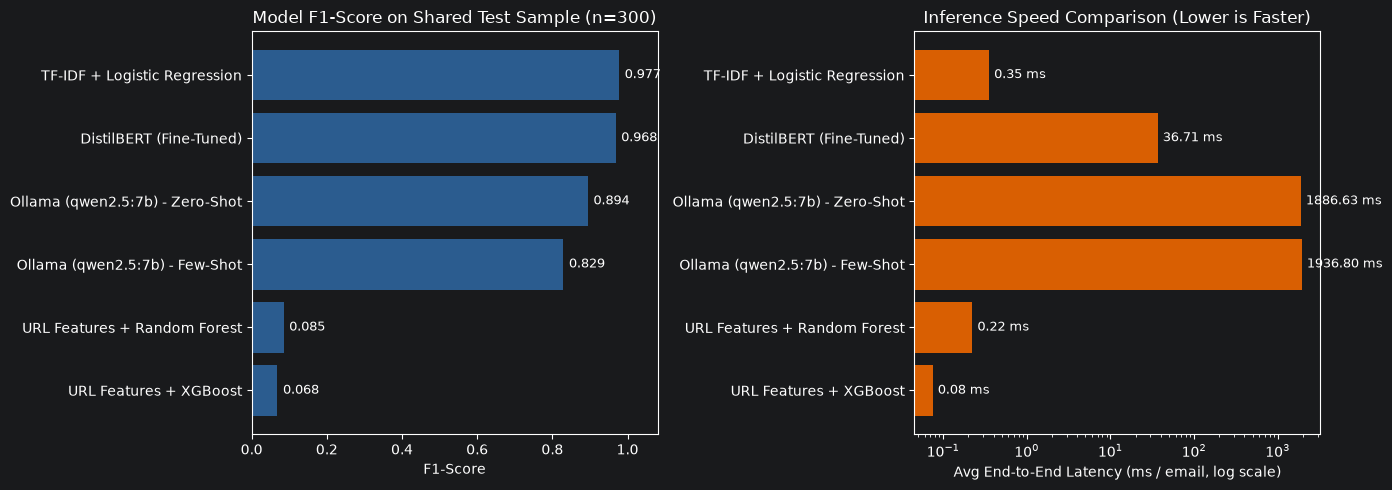

In [4]:
plot_df = sample_comp.sort_values(by="f1", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. F1-Score comparison
axes[0].barh(plot_df["model"], plot_df["f1"], color="#2b5c8f")
axes[0].set_xlim(0, 1.08)
axes[0].set_xlabel("F1-Score")
axes[0].set_title("Model F1-Score on Shared Test Sample (n=300)")
for idx, val in enumerate(plot_df["f1"]):
    axes[0].text(val + 0.015, idx, f"{val:.3f}", va="center", fontsize=9)

# 2. End-to-End Inference Latency (log scale)
axes[1].barh(plot_df["model"], plot_df["avg_e2e_inference_ms"], color="#d95f02")
axes[1].set_xscale("log")
axes[1].set_xlabel("Avg End-to-End Latency (ms / email, log scale)")
axes[1].set_title("Inference Speed Comparison (Lower is Faster)")
for idx, val in enumerate(plot_df["avg_e2e_inference_ms"]):
    axes[1].text(val * 1.15, idx, f"{val:.2f} ms", va="center", fontsize=9)

plt.tight_layout()
plt.show()

## Preliminary Findings & Error Interpretation
* **Textual Models (`TF-IDF + LogReg` vs. `DistilBERT`):** Both models achieve strong performance on the full test set (`F1 = 0.9763` and `0.9698`, respectively). Notably, `TF-IDF + Logistic Regression` slightly outperforms `DistilBERT` while being >100x faster on CPU (`0.33 ms` vs `41.4 ms` per email in batch mode) and requiring only `0.89 MB` of storage compared to `256.1 MB`.
* **URL-Only Models (`Random Forest` / `XGBoost`):** Although precision on flagged emails is relatively high (`0.75–0.80`), overall recall remains low (`~0.055`, `F1 ≈ 0.10–0.11`). This happens because ~77% of emails in the corpus contain no explicit `http/www` URLs, forcing URL-only classifiers to default to the majority legitimate class (~62.7% baseline accuracy).
* **Next Steps:** Complete the cross-dataset generalization experiment (evaluating models trained on full bodies against the subject-only dataset and vice versa), tighten leakage grouping to exact tokenized inputs, and perform qualitative Error Analysis on misclassified emails.